In [1]:
!pip install pycocotools

v2 train

In [2]:
# ===============================
# BLOCK 4: TRAIN MULTICLASS FASTER R-CNN
# ===============================

import os
import torch
import collections
import torchvision.models.detection as detection
from torchvision.datasets import CocoDetection
from torchvision import transforms
from torch.utils.data import DataLoader

# -------- Device --------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -------- Paths --------
base_dir = "/home/ehr/Desktop/anupama/CPP_Strawberry_RGB_MS_2025/Unprocessed_data/all.v1i.coco"
train_dir = os.path.join(base_dir, "train")
train_ann = os.path.join(train_dir, "_annotations.coco.json")

# -------- Hyperparameters --------
num_epochs = 10
batch_size = 2
lr = 1e-4

# -------- Dataset --------
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = CocoDetection(train_dir, train_ann, transform=transform)

def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

# -------- Build class mapping --------
raw_ids = sorted({obj["category_id"] for _, anns in train_dataset for obj in anns})
id_map = {rid: i + 1 for i, rid in enumerate(raw_ids)}  # 1..K
num_classes = len(raw_ids) + 1  # + background

print("Raw COCO category ids:", raw_ids)
print("Id map:", id_map)
print("num_classes (including background):", num_classes)

# -------- Model --------
weights = detection.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
model = detection.fasterrcnn_mobilenet_v3_large_fpn(weights=weights)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = detection.faster_rcnn.FastRCNNPredictor(
    in_features, num_classes
)

model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# -------- COCO → model target --------
def coco_to_target(anns):
    boxes, labels = [], []
    for obj in anns:
        cid = obj["category_id"]
        if cid not in id_map:
            continue
        x, y, w, h = obj["bbox"]
        boxes.append([x, y, x + w, y + h])
        labels.append(id_map[cid])
    if not boxes:
        return None
    return {
        "boxes": torch.tensor(boxes, dtype=torch.float32, device=device),
        "labels": torch.tensor(labels, dtype=torch.int64, device=device),
    }

# -------- Training loop --------
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    steps = 0

    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets_proc = [coco_to_target(t) for t in targets]
        pairs = [(img, tgt) for img, tgt in zip(images, targets_proc) if tgt is not None]

        if not pairs:
            continue

        images_kept, targets_kept = zip(*pairs)

        loss_dict = model(images_kept, targets_kept)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        steps += 1

    print(f"Epoch {epoch+1}/{num_epochs} | Loss: {epoch_loss/max(1,steps):.4f}")

torch.save(model.state_dict(), "frcnn_trained.pt")
print("Saved frcnn_trained.pt")


Using device: cuda
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Raw COCO category ids: [1, 2, 3, 4, 5]
Id map: {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
num_classes (including background): 6
Epoch 1/10 | Loss: 1.1627
Epoch 2/10 | Loss: 1.0703
Epoch 3/10 | Loss: 1.0382
Epoch 4/10 | Loss: 1.0312
Epoch 5/10 | Loss: 1.0102
Epoch 6/10 | Loss: 1.0078
Epoch 7/10 | Loss: 0.9954
Epoch 8/10 | Loss: 0.9820
Epoch 9/10 | Loss: 0.9674
Epoch 10/10 | Loss: 0.9558
Saved frcnn_trained.pt


v2 test

In [3]:
# ===============================
# BLOCK 5: VALIDATION + DETECTION METRICS
# ===============================

import numpy as np
from torchvision.ops import box_iou
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# -------- Validation dataset --------
val_dir = os.path.join(base_dir, "valid")
val_ann = os.path.join(val_dir, "_annotations.coco.json")

val_dataset = CocoDetection(val_dir, val_ann, transform=transform)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn)

# -------- Load trained model --------
model.load_state_dict(torch.load("frcnn_trained.pt", map_location=device))
model.to(device).eval()

def evaluate_detection(model, loader, conf_thr=0.2, iou_thr=0.5):
    TP = FP = FN = 0

    with torch.no_grad():
        for images, targets in loader:
            images = [img.to(device) for img in images]
            preds = model(images)

            for pred, ann in zip(preds, targets):
                gt_boxes, gt_labels = [], []
                for obj in ann:
                    cid = obj["category_id"]
                    if cid not in id_map:
                        continue
                    x,y,w,h = obj["bbox"]
                    gt_boxes.append([x,y,x+w,y+h])
                    gt_labels.append(id_map[cid])

                gt_boxes = torch.tensor(gt_boxes, device=device) if gt_boxes else torch.empty((0,4), device=device)
                gt_labels = torch.tensor(gt_labels, device=device) if gt_labels else torch.empty((0,), device=device)

                keep = pred["scores"] >= conf_thr
                pb = pred["boxes"][keep]
                pl = pred["labels"][keep]

                if gt_boxes.numel() == 0:
                    FP += pb.size(0)
                    continue
                if pb.numel() == 0:
                    FN += gt_boxes.size(0)
                    continue

                ious = box_iou(pb, gt_boxes)
                matched = set()

                for i in range(pb.size(0)):
                    best_iou, best_j = 0, -1
                    for j in range(gt_boxes.size(0)):
                        if j in matched or pl[i] != gt_labels[j]:
                            continue
                        if ious[i,j] > best_iou:
                            best_iou, best_j = ious[i,j], j
                    if best_iou >= iou_thr:
                        TP += 1
                        matched.add(best_j)
                    else:
                        FP += 1

                FN += gt_boxes.size(0) - len(matched)

    precision = TP / max(1, TP + FP)
    recall = TP / max(1, TP + FN)
    f1 = 2 * precision * recall / max(1e-6, precision + recall)

    print(f"TP={TP} FP={FP} FN={FN}")
    print(f"Precision={precision:.3f} Recall={recall:.3f} F1={f1:.3f}")

    return precision, recall, f1

evaluate_detection(model, val_loader)


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


/tmp/ipykernel_578621/4127586491.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("frcnn_trained.pt", map_location=device))


TP=1045 FP=2838 FN=1216
Precision=0.269 Recall=0.462 F1=0.340


(0.26912181303116145, 0.46218487394957986, 0.3401692708333333)

v3 train

In [4]:
# ===============================
# BLOCK 7: MULTICLASS METRICS + mAP (fixed: consistent y_true/y_pred lengths)
# ===============================

import torch  # PyTorch core
import numpy as np  # numeric helpers
from collections import defaultdict  # per-class counting
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # classic metrics
from torchvision.ops import box_iou  # IoU computation for box matching
import warnings  # for gentle fallbacks

# Try to import pycocotools for official COCO mAP; if unavailable we'll use a fallback.
try:
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    HAVE_PYCOCO = True
except Exception:
    HAVE_PYCOCO = False
    warnings.warn("pycocotools not available — COCO mAP computation will be skipped. Install pycocotools for exact mAP.")

# Helper: convert box format if needed (we expect GT in [x,y,w,h] often).
def xywh_to_xyxy(boxes_xywh):
    boxes_xywh = np.asarray(boxes_xywh, dtype=float)
    if boxes_xywh.size == 0:
        return np.zeros((0, 4), dtype=float)
    x, y, w, h = boxes_xywh[:, 0], boxes_xywh[:, 1], boxes_xywh[:, 2], boxes_xywh[:, 3]
    return np.stack([x, y, x + w, y + h], axis=1)

# Main evaluation function: IoU matching + per-class metrics + optional COCO mAP
def evaluate_multiclass(
    model,
    loader,
    id_map=None,           # dict: original_category_id -> model_label (int). If None, assume labels already contiguous.
    conf_thr=0.25,        # confidence threshold to consider a detection
    iou_thr=0.5,          # IoU threshold to match pred -> gt
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    compute_coco_map=False,  # set True if you have COCO annotation file and pycocotools
    coco_gt_ann_file=None,   # path to COCO-format val annotations if compute_coco_map True
):
    """
    Evaluate object detection in a multiclass setup by greedy IoU matching.
    Returns results dict with per-class TP/FP/FN and overall sklearn-style metrics.
    """

    model.eval()                     # evaluation mode
    model.to(device)                 # ensure model on device

    # If id_map provided, build inverse mapping for reporting/coco export
    inv_id_map = {v: k for k, v in id_map.items()} if id_map is not None else None

    # Counters per class
    tp = defaultdict(int)
    fp = defaultdict(int)
    fn = defaultdict(int)

    # Best-effort per-object lists for sklearn metrics (one entry per GT)
    y_true_list = []
    y_pred_list = []

    # For COCO mAP (optional)
    coco_dets = []
    image_id_counter = 0

    with torch.no_grad():
        for images, targets in loader:
            # move images to device and forward
            images = [img.to(device) for img in images]
            preds = model(images)

            # iterate through images in batch
            for pred, ann in zip(preds, targets):
                # collect ground-truth boxes and labels (mapped)
                gt_boxes_xyxy = []
                gt_labels_mapped = []

                for obj in ann:
                    orig_cat = obj.get("category_id", obj.get("category", None))
                    # include only gt categories present in id_map if provided
                    if id_map is None or orig_cat in id_map:
                        b = obj["bbox"]  # expected [x,y,w,h]
                        x, y, w, h = float(b[0]), float(b[1]), float(b[2]), float(b[3])
                        gt_boxes_xyxy.append([x, y, x + w, y + h])
                        mapped_label = id_map[orig_cat] if id_map is not None else orig_cat
                        gt_labels_mapped.append(int(mapped_label))

                # numpy arrays for convenience
                if len(gt_boxes_xyxy) == 0:
                    gt_boxes = np.zeros((0, 4), dtype=float)
                    gt_labels_mapped = np.array([], dtype=int)
                else:
                    gt_boxes = np.asarray(gt_boxes_xyxy, dtype=float)
                    gt_labels_mapped = np.asarray(gt_labels_mapped, dtype=int)

                # prepare predictions, filter by score threshold
                pred_scores = pred.get("scores", torch.tensor([])).cpu()
                keep_mask = pred_scores >= conf_thr
                pred_boxes = pred.get("boxes", torch.tensor([]))[keep_mask].cpu().numpy() if len(pred.get("boxes", [])) else np.zeros((0, 4))
                pred_labels = pred.get("labels", torch.tensor([]))[keep_mask].cpu().numpy().astype(int) if len(pred.get("labels", [])) else np.array([], dtype=int)
                pred_scores = pred_scores[keep_mask].cpu().numpy() if len(pred_scores[keep_mask]) else np.array([], dtype=float)

                # If there are no predictions: every GT is a false negative.
                if pred_boxes.shape[0] == 0:
                    for lbl in gt_labels_mapped:
                        fn[int(lbl)] += 1
                    # Append a per-GT entry (pred = -1 meaning missed) — THIS is the only place we append for GTs when preds are empty.
                    for lbl in gt_labels_mapped.tolist():
                        y_true_list.append(int(lbl))
                        y_pred_list.append(-1)
                    image_id_counter += 1
                    continue

                # If there are predictions but no GTs: all predictions are false positives.
                if gt_boxes.shape[0] == 0:
                    for lbl in pred_labels:
                        fp[int(lbl)] += 1
                    # Add predictions to coco_dets for COCO-eval if needed
                    for pb, pl, ps in zip(pred_boxes, pred_labels, pred_scores):
                        x1, y1, x2, y2 = pb
                        coco_dets.append({
                            "image_id": image_id_counter,
                            "category_id": int(inv_id_map[pl]) if inv_id_map is not None and pl in inv_id_map else int(pl),
                            "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                            "score": float(ps)
                        })
                    image_id_counter += 1
                    # No GTs to append to y_true/y_pred (we keep y lists 1-per-GT only)
                    continue

                # compute IoU matrix between preds and GTs
                iou_mat = box_iou(torch.tensor(pred_boxes, dtype=torch.float32),
                                  torch.tensor(gt_boxes, dtype=torch.float32)).numpy()

                # Greedy matching by IoU (largest first)
                matched_pred_idx = set()
                matched_gt_idx = set()
                cand = [(pi, gi, float(iou_mat[pi, gi]))
                        for pi in range(iou_mat.shape[0])
                        for gi in range(iou_mat.shape[1])]
                cand.sort(key=lambda x: x[2], reverse=True)

                for pi, gi, iou in cand:
                    if iou < iou_thr:
                        break
                    if pi in matched_pred_idx or gi in matched_gt_idx:
                        continue
                    if int(pred_labels[pi]) == int(gt_labels_mapped[gi]):
                        cls = int(pred_labels[pi])
                        tp[cls] += 1
                        matched_pred_idx.add(pi)
                        matched_gt_idx.add(gi)
                    else:
                        # label mismatch at high IoU: count as FP (pred) + FN (gt)
                        cls_pred = int(pred_labels[pi])
                        cls_gt = int(gt_labels_mapped[gi])
                        fp[cls_pred] += 1
                        fn[cls_gt] += 1
                        matched_pred_idx.add(pi)
                        matched_gt_idx.add(gi)

                # unmatched preds => false positives
                for pi in range(pred_boxes.shape[0]):
                    if pi not in matched_pred_idx:
                        cls = int(pred_labels[pi])
                        fp[cls] += 1

                # unmatched gts => false negatives
                for gi in range(gt_boxes.shape[0]):
                    if gi not in matched_gt_idx:
                        cls = int(gt_labels_mapped[gi])
                        fn[cls] += 1

                # Now append exactly one (y_true, y_pred) pair per GT for sklearn metrics:
                # find for each GT the best predicted box (by IoU); if best IoU < iou_thr -> pred = -1
                for gi in range(gt_boxes.shape[0]):
                    best_pi = int(np.argmax(iou_mat[:, gi]))
                    best_iou = float(np.max(iou_mat[:, gi]))
                    true_lbl = int(gt_labels_mapped[gi])
                    if best_iou >= iou_thr:
                        pred_lbl = int(pred_labels[best_pi])
                    else:
                        pred_lbl = -1
                    y_true_list.append(true_lbl)
                    y_pred_list.append(pred_lbl)

                # collect predictions for COCO evaluation (xywh)
                for pb, pl, ps in zip(pred_boxes, pred_labels, pred_scores):
                    x1, y1, x2, y2 = pb
                    coco_dets.append({
                        "image_id": image_id_counter,
                        "category_id": int(inv_id_map[pl]) if inv_id_map is not None and pl in inv_id_map else int(pl),
                        "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                        "score": float(ps)
                    })

                image_id_counter += 1

    # Compute per-class metrics from TP/FP/FN
    per_class_metrics = {}
    classes_seen = sorted(set(list(tp.keys()) + list(fp.keys()) + list(fn.keys())))
    for cls in classes_seen:
        TP = tp.get(cls, 0)
        FP = fp.get(cls, 0)
        FN = fn.get(cls, 0)
        prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        rec = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        per_class_metrics[cls] = {"TP": TP, "FP": FP, "FN": FN, "precision": prec, "recall": rec, "f1": f1}

    # Compute overall sklearn metrics on the per-GT lists (they are now guaranteed same length)
    if len(y_true_list) > 0:
        y_true_arr = np.array(y_true_list)
        y_pred_arr = np.array(y_pred_list)
        # sklearn will accept -1 as a label; we keep it to penalize missed detections.
        try:
            overall_acc = accuracy_score(y_true_arr, y_pred_arr)
            overall_prec = precision_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)
            overall_rec = recall_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)
            overall_f1 = f1_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)
        except Exception:
            overall_acc = overall_prec = overall_rec = overall_f1 = 0.0
    else:
        overall_acc = overall_prec = overall_rec = overall_f1 = 0.0

    # Print summary
    print("Per-class metrics (mapped labels):")
    for cls, m in per_class_metrics.items():
        mapped_orig = inv_id_map[cls] if inv_id_map is not None and cls in inv_id_map else cls
        print(f" Class {cls} (orig id {mapped_orig}): TP={m['TP']} FP={m['FP']} FN={m['FN']} P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f}")

    print("\nOverall metrics (best-effort per-object):")
    print(f" Accuracy: {overall_acc:.4f} Precision: {overall_prec:.4f} Recall: {overall_rec:.4f} F1: {overall_f1:.4f}")

    results = {
        "per_class": per_class_metrics,
        "overall": {
            "accuracy": overall_acc,
            "precision": overall_prec,
            "recall": overall_rec,
            "f1": overall_f1
        }
    }

    # Optional COCO mAP@0.5 using pycocotools
    if compute_coco_map and HAVE_PYCOCO and coco_gt_ann_file is not None:
        import json, tempfile
        coco_gt = COCO(coco_gt_ann_file)
        tmpf = tempfile.NamedTemporaryFile(mode="w+", suffix=".json", delete=False)
        json.dump(coco_dets, tmpf)
        tmpf.flush()
        tmpf.close()
        coco_dt = coco_gt.loadRes(tmpf.name)
        coco_eval = COCOeval(coco_gt, coco_dt, "bbox")
        coco_eval.params.iouThrs = np.array([0.5])  # mAP@0.5
        coco_eval.evaluate()
        coco_eval.accumulate()
        coco_eval.summarize()
        results["coco_map@0.5"] = float(coco_eval.stats[0])

    elif compute_coco_map and not HAVE_PYCOCO:
        warnings.warn("Requested COCO mAP but pycocotools is not installed; skipping COCO mAP calculation.")

    return results

# Example call (no pycocotools):
# res = evaluate_multiclass(model, val_loader, id_map=globals().get("id_map", None), conf_thr=0.25, iou_thr=0.5)


Running Test A...
TEST A: score>=0.25, topK=50, images=119
  after score only: mean=26.8, p90=55.2, max=88
  after topK      : mean=24.5, p90=50.0, max=50

Running Test B...


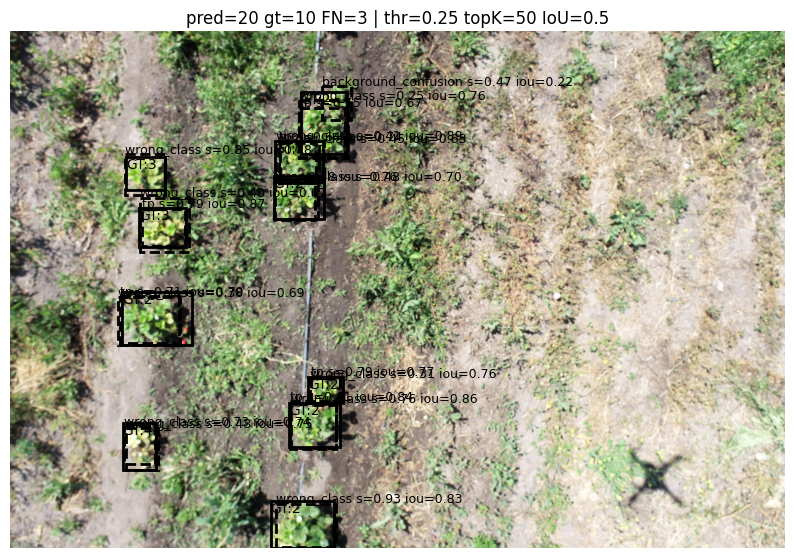

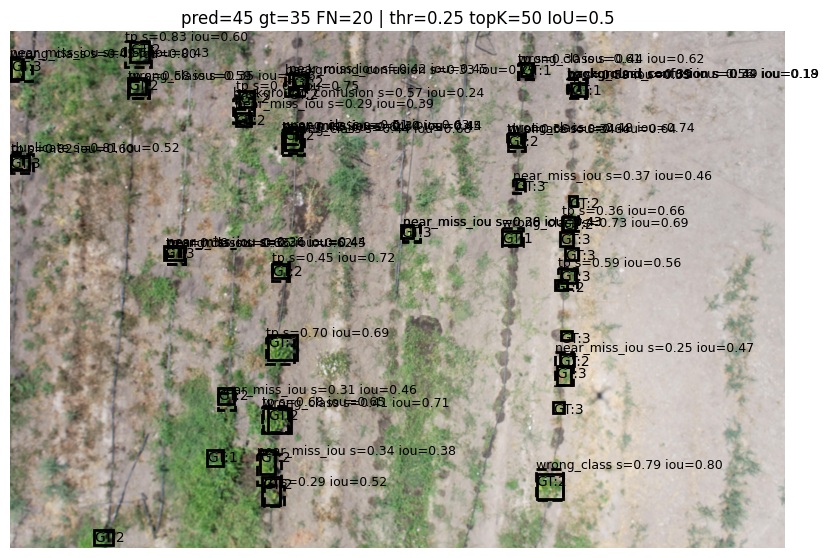

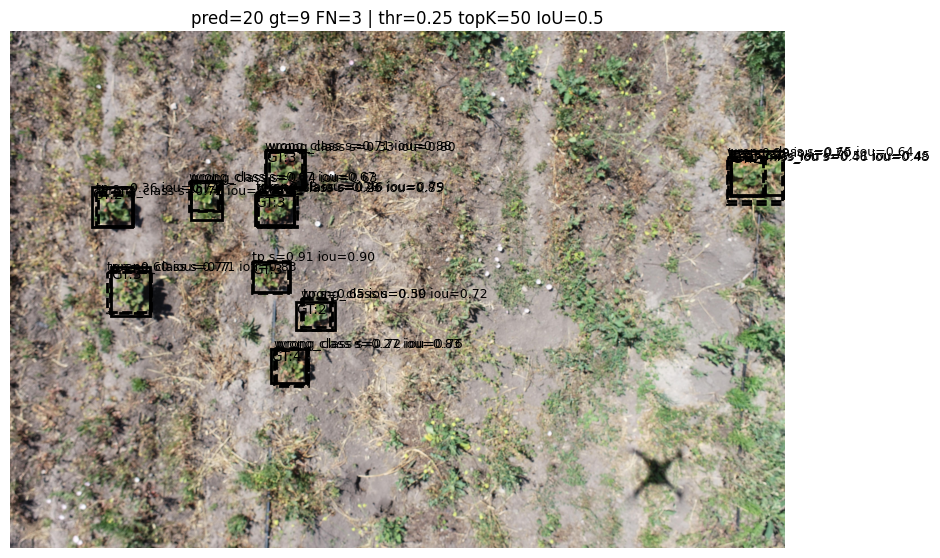

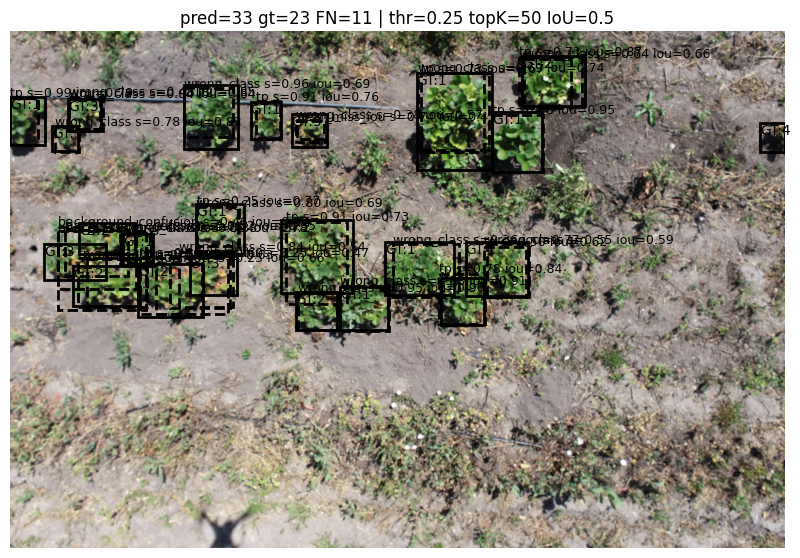

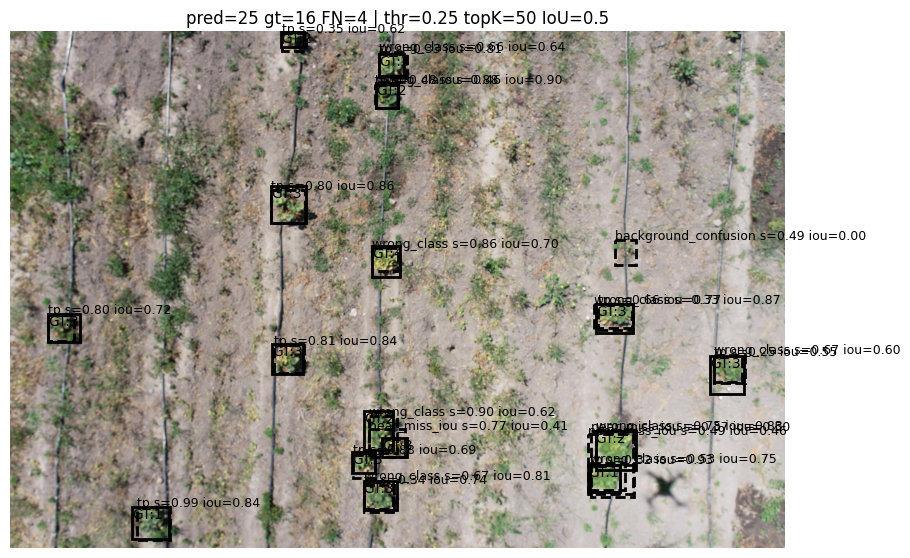

...

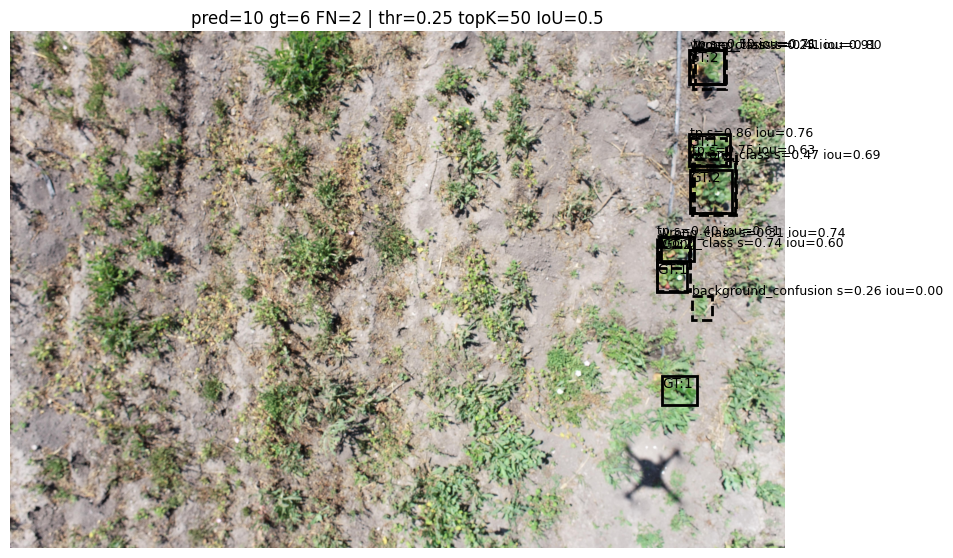

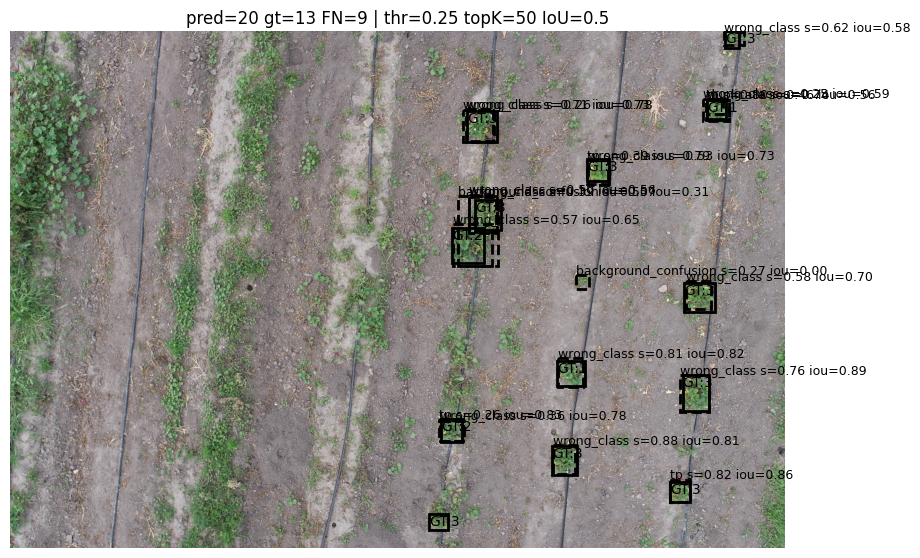

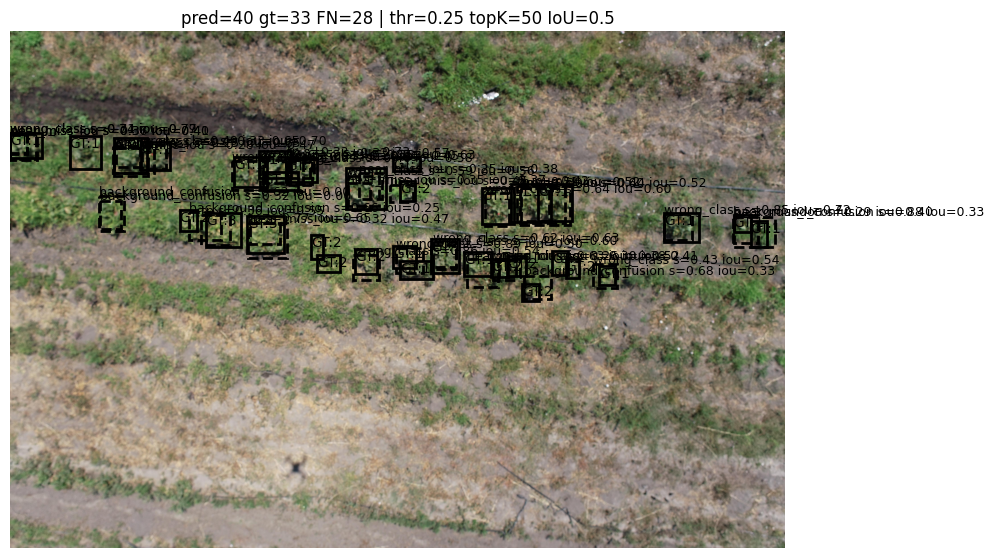

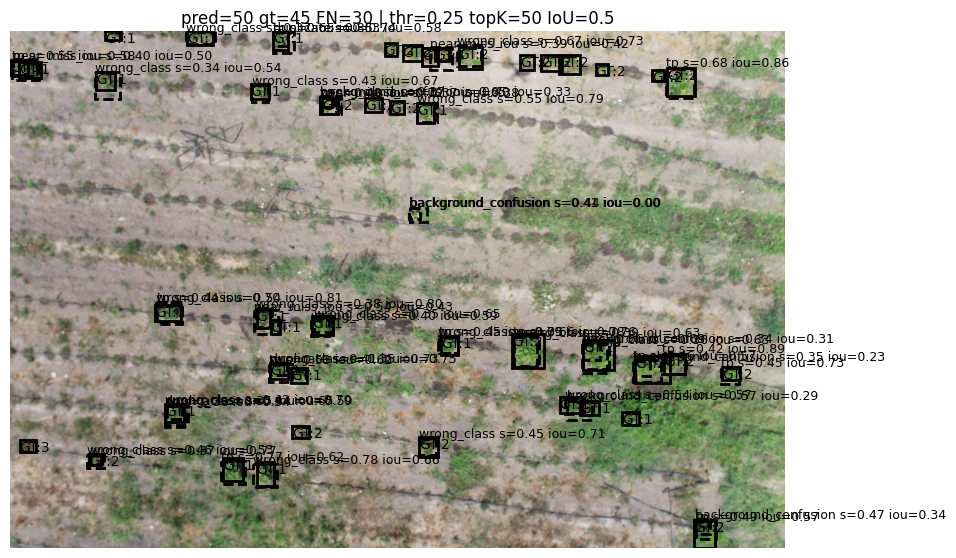

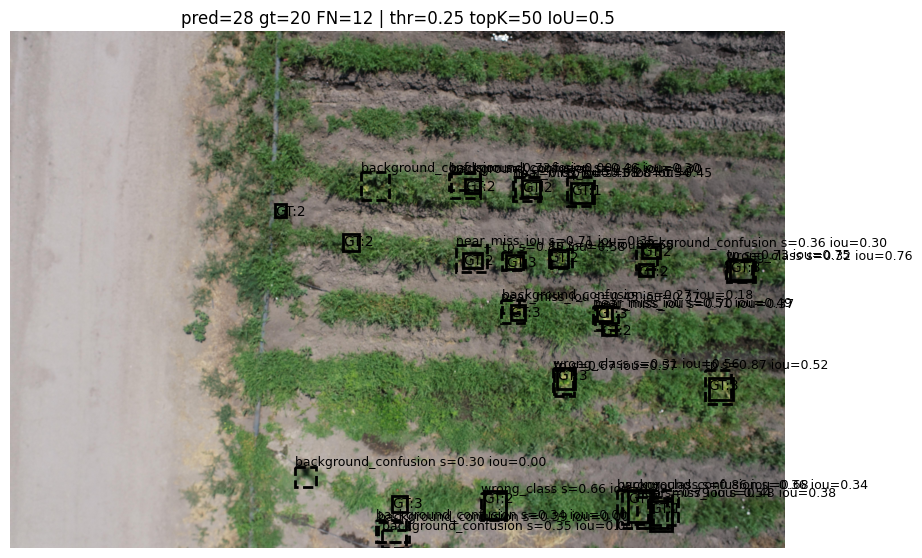

TEST B summary: {'tp': 149, 'duplicate': 11, 'wrong_class': 204, 'near_miss_iou': 74, 'background_confusion': 91}
Manual: label 'annotation missing' if prediction is real but GT missing.


{'tp': 149,
 'duplicate': 11,
 'wrong_class': 204,
 'near_miss_iou': 74,
 'background_confusion': 91}

In [14]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchvision.ops import box_iou

SCORE_THR = 0.25
IOU_THR   = 0.50
TOPK      = 50
NUM_VIS   = 20
MAX_A     = 200

def tdict(t):
    """
    Converts target to {"boxes": Tensor[N,4], "labels": Tensor[N]}.
    Supports:
      - dict with boxes/labels
      - (boxes, labels)
      - list of ann dicts with bbox + category_id (COCO style)
    """
    # dict style
    if isinstance(t, dict):
        return {"boxes": t["boxes"], "labels": t["labels"]}

    # tuple/list (boxes, labels)
    if isinstance(t, (tuple, list)) and len(t) >= 2:
        a, b = t[0], t[1]
        if isinstance(a, torch.Tensor) and a.ndim == 2 and a.shape[-1] == 4:
            return {"boxes": a, "labels": b if isinstance(b, torch.Tensor) else torch.as_tensor(b)}
        if isinstance(b, torch.Tensor) and b.ndim == 2 and b.shape[-1] == 4:
            return {"boxes": b, "labels": a if isinstance(a, torch.Tensor) else torch.as_tensor(a)}

    # COCO style: list of dict annotations
    if isinstance(t, list) and (len(t) == 0 or isinstance(t[0], dict)):
        if len(t) == 0:
            return {"boxes": torch.zeros((0,4), dtype=torch.float32), "labels": torch.zeros((0,), dtype=torch.int64)}
        boxes = []
        labels = []
        for ann in t:
            # bbox could be [x,y,w,h] or already [x1,y1,x2,y2]
            bb = ann.get("bbox", None)
            if bb is None:
                raise KeyError("COCO ann dict missing 'bbox'")
            bb = torch.as_tensor(bb, dtype=torch.float32)

            if bb.numel() == 4:
                x, y, w, h = bb.tolist()
                # assume COCO xywh; convert to xyxy
                x1, y1, x2, y2 = x, y, x + w, y + h
                boxes.append([x1,y1,x2,y2])
            else:
                raise ValueError("bbox is not length-4")

            cid = ann.get("category_id", ann.get("label", ann.get("labels", None)))
            if cid is None:
                raise KeyError("COCO ann dict missing category_id/label")
            labels.append(int(cid))

        return {"boxes": torch.tensor(boxes, dtype=torch.float32),
                "labels": torch.tensor(labels, dtype=torch.int64)}

    raise TypeError(f"Unsupported target format: {type(t)}")

def filt(pred, score_thr=0.25, topk=50):
    s = pred["scores"]
    keep = s >= score_thr
    b = pred["boxes"][keep]
    s = pred["scores"][keep]
    l = pred["labels"][keep]
    if s.numel():
        o = torch.argsort(s, descending=True)
        b, s, l = b[o], s[o], l[o]
    if topk and s.numel() > topk:
        b, s, l = b[:topk], s[:topk], l[:topk]
    return b.detach().cpu(), s.detach().cpu(), l.detach().cpu()

def match(pred_boxes, pred_labels, gt_boxes, gt_labels, iou_thr=0.5):
    nP, nG = len(pred_boxes), len(gt_boxes)
    gt_used = torch.zeros(nG, dtype=torch.bool)
    reasons, best_iou = [], []
    if nG == 0:
        return ["background_confusion"]*nP, gt_used, [0.0]*nP

    ious = box_iou(pred_boxes.float(), gt_boxes.float())
    for i in range(nP):
        j = int(torch.argmax(ious[i]).item())
        bi = float(ious[i, j].item())
        best_iou.append(bi)

        if bi < iou_thr:
            reasons.append("near_miss_iou" if bi >= (iou_thr - 0.15) else "background_confusion")
        elif int(pred_labels[i]) != int(gt_labels[j]):
            reasons.append("wrong_class")
        elif gt_used[j]:
            reasons.append("duplicate")
        else:
            reasons.append("tp")
            gt_used[j] = True
    return reasons, gt_used, best_iou

def show(img, gt_boxes, gt_labels, pred_boxes, pred_scores, reasons, best_ious, title=""):
    img = img.detach().cpu()
    if img.ndim == 3 and img.shape[0] in (1,3): img = img.permute(1,2,0)
    img = np.clip(img.numpy(), 0, 1)

    plt.figure(figsize=(10,8))
    plt.imshow(img); ax = plt.gca()

    for k in range(len(gt_boxes)):
        x1,y1,x2,y2 = gt_boxes[k].tolist()
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, linewidth=2))
        ax.text(x1, y1, f"GT:{int(gt_labels[k])}", fontsize=10, va="top")

    for i in range(len(pred_boxes)):
        x1,y1,x2,y2 = pred_boxes[i].tolist()
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, linewidth=2, linestyle="--"))
        ax.text(x1, max(0,y1-10), f"{reasons[i]} s={pred_scores[i]:.2f} iou={best_ious[i]:.2f}", fontsize=9)

    plt.title(title); plt.axis("off"); plt.show()

def test_a(model, loader, device, score_thr=0.25, topk=50, max_imgs=200):
    model.eval()
    c1, c2, seen = [], [], 0
    with torch.no_grad():
        for batch in loader:
            imgs = batch[0]
            outs = model([im.to(device) for im in imgs])
            for out in outs:
                c1.append(int((out["scores"] >= score_thr).sum().item()))
                b,s,l = filt(out, score_thr, topk)
                c2.append(len(s))
                seen += 1
                if seen >= max_imgs: break
            if seen >= max_imgs: break
    a1, a2 = np.array(c1), np.array(c2)
    print(f"TEST A: score>={score_thr}, topK={topk}, images={len(a1)}")
    print(f"  after score only: mean={a1.mean():.1f}, p90={np.percentile(a1,90):.1f}, max={a1.max()}")
    print(f"  after topK      : mean={a2.mean():.1f}, p90={np.percentile(a2,90):.1f}, max={a2.max()}")
    return c1, c2

def test_b(model, loader, device, score_thr=0.25, topk=50, iou_thr=0.5, n=20):
    model.eval()
    counts = {"tp":0, "duplicate":0, "wrong_class":0, "near_miss_iou":0, "background_confusion":0}
    shown = 0
    with torch.no_grad():
        for batch in loader:
            imgs, tgts = batch[0], batch[1]
            for img, tgt in zip(imgs, tgts):
                out = model([img.to(device)])[0]
                pb, ps, pl = filt(out, score_thr, topk)

                td = tdict(tgt)
                gb = td["boxes"].detach().cpu()
                gl = td["labels"].detach().cpu()

                reasons, gt_used, best_ious = match(pb, pl, gb, gl, iou_thr)
                for r in reasons: counts[r] += 1
                fn = int((~gt_used).sum().item())

                show(img, gb, gl, pb, ps, reasons, best_ious,
                     title=f"pred={len(ps)} gt={len(gb)} FN={fn} | thr={score_thr} topK={topk} IoU={iou_thr}")

                shown += 1
                if shown >= n: break
            if shown >= n: break

    print("TEST B summary:", counts)
    print("Manual: label 'annotation missing' if prediction is real but GT missing.")
    return counts

print("Running Test A...")
test_a(model, val_loader, device, SCORE_THR, TOPK, MAX_A)

print("\nRunning Test B...")
test_b(model, val_loader, device, SCORE_THR, TOPK, IOU_THR, NUM_VIS)


In [20]:
import numpy as np
import torch
from torchvision.ops import box_iou

def as_target_dict(t):
    # dict case
    if isinstance(t, dict):
        return {"boxes": t["boxes"], "labels": t["labels"]}

    # tuple list (boxes, labels) or (labels, boxes)
    if isinstance(t, (list, tuple)) and len(t) >= 2:
        a, b = t[0], t[1]
        if isinstance(a, torch.Tensor) and a.ndim == 2 and a.shape[-1] == 4:
            return {"boxes": a, "labels": b if isinstance(b, torch.Tensor) else torch.as_tensor(b)}
        if isinstance(b, torch.Tensor) and b.ndim == 2 and b.shape[-1] == 4:
            return {"boxes": b, "labels": a if isinstance(a, torch.Tensor) else torch.as_tensor(a)}

    # COCO style list of dict annotations
    if isinstance(t, list) and (len(t) == 0 or isinstance(t[0], dict)):
        if len(t) == 0:
            return {
                "boxes": torch.zeros((0,4), dtype=torch.float32),
                "labels": torch.zeros((0,), dtype=torch.int64),
            }
        boxes, labels = [], []
        for ann in t:
            bb = ann.get("bbox")
            cid = ann.get("category_id", ann.get("label"))
            x, y, w, h = bb
            boxes.append([x, y, x + w, y + h])  # xywh to xyxy
            labels.append(int(cid))
        return {"boxes": torch.tensor(boxes, dtype=torch.float32),
                "labels": torch.tensor(labels, dtype=torch.int64)}

    raise TypeError(f"Unsupported target format: {type(t)}")

def filter_preds_frcnn(pred, score_thr, topk):
    scores = pred["scores"]
    keep = scores >= score_thr
    boxes = pred["boxes"][keep]
    scores = pred["scores"][keep]
    labels = pred["labels"][keep]

    if scores.numel() > 0:
        order = torch.argsort(scores, descending=True)
        boxes, scores, labels = boxes[order], scores[order], labels[order]

    if topk is not None and scores.numel() > topk:
        boxes, scores, labels = boxes[:topk], scores[:topk], labels[:topk]

    return boxes.detach().cpu(), scores.detach().cpu(), labels.detach().cpu()

def greedy_match_counts(pred_boxes, pred_labels, gt_boxes, gt_labels, iou_thr):
    """
    One prediction can match at most one GT.
    One GT can match at most one prediction.
    Match requires IoU >= iou_thr and same class id.
    """
    TP = 0
    FP = 0
    num_gt = gt_boxes.shape[0]
    used = torch.zeros((num_gt,), dtype=torch.bool)

    if pred_boxes.shape[0] == 0:
        FN = int(num_gt)
        return TP, FP, FN

    if num_gt == 0:
        TP = 0
        FP = int(pred_boxes.shape[0])
        FN = 0
        return TP, FP, FN

    ious = box_iou(pred_boxes.float(), gt_boxes.float())

    for i in range(pred_boxes.shape[0]):
        j = int(torch.argmax(ious[i]).item())
        best_iou = float(ious[i, j].item())

        if best_iou < iou_thr:
            FP += 1
            continue

        if int(pred_labels[i]) != int(gt_labels[j]):
            FP += 1
            continue

        if used[j]:
            FP += 1
            continue

        used[j] = True
        TP += 1

    FN = int((~used).sum().item())
    return TP, FP, FN

def eval_frcnn(model, loader, device, score_thr, topk, iou_thr, max_images=None):
    model.eval()
    TP = FP = FN = 0
    seen = 0

    with torch.no_grad():
        for batch in loader:
            images, targets = batch[0], batch[1]
            outputs = model([img.to(device) for img in images])

            for out, tgt in zip(outputs, targets):
                td = as_target_dict(tgt)
                gt_boxes = td["boxes"].detach().cpu()
                gt_labels = td["labels"].detach().cpu()

                pb, ps, pl = filter_preds_frcnn(out, score_thr, topk)

                tp, fp, fn = greedy_match_counts(pb, pl, gt_boxes, gt_labels, iou_thr)
                TP += tp; FP += fp; FN += fn

                seen += 1
                if max_images and seen >= max_images:
                    break
            if max_images and seen >= max_images:
                break

    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return TP, FP, FN, precision, recall, f1

def grid_search_frcnn(model, loader, device,
                      score_list=(0.25, 0.35, 0.5, 0.65),
                      topk_list=(50, 20, 10),
                      iou_thr=0.5,
                      max_images=None):
    rows = []
    for s in score_list:
        for k in topk_list:
            TP, FP, FN, p, r, f1 = eval_frcnn(model, loader, device, s, k, iou_thr, max_images=max_images)
            rows.append((s, k, TP, FP, FN, p, r, f1))

    rows.sort(key=lambda x: x[-1], reverse=True)  # best F1 first

    print("score  topK   TP     FP     FN     precision  recall  F1")
    for s, k, TP, FP, FN, p, r, f1 in rows:
        print(f"{s:0.2f}  {k:4d}  {TP:5d}  {FP:5d}  {FN:5d}   {p:0.3f}    {r:0.3f}  {f1:0.3f}")

    best = rows[0]
    print("\nBest by F1:", best)
    return rows

# Run this
    grid_search_frcnn(model, val_loader, device,
                 score_list=(0.25, 0.35, 0.45, 0.5, 0.6),
                  topk_list=(50, 20, 10),
                  iou_thr=0.5,
                  max_images=None)


v3 test

In [21]:
import torch
import numpy as np
from torchvision.ops import box_iou, nms

def coco_targets_to_xyxy(target):
    """
    target is COCO style: list of dicts, each has bbox [x,y,w,h] and category_id
    returns gt_boxes (N,4) in xyxy and gt_labels (N,)
    """
    if len(target) == 0:
        return torch.zeros((0,4), dtype=torch.float32), torch.zeros((0,), dtype=torch.int64)

    boxes = []
    labels = []
    for obj in target:
        x, y, w, h = obj["bbox"]
        boxes.append([x, y, x + w, y + h])
        labels.append(int(obj["category_id"]))
    return torch.tensor(boxes, dtype=torch.float32), torch.tensor(labels, dtype=torch.int64)

def postprocess_preds(pred, conf_thr=0.5, nms_iou=0.5, topk=20):
    """
    Keep confident boxes, apply NMS to remove duplicates, cap topK
    returns boxes, scores, labels on CPU
    """
    boxes = pred["boxes"].detach().cpu()
    scores = pred["scores"].detach().cpu()
    labels = pred["labels"].detach().cpu()

    keep = scores >= conf_thr
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]

    if scores.numel() == 0:
        return boxes, scores, labels

    # NMS per class so different classes do not suppress each other
    keep_all = []
    for c in labels.unique():
        idx = (labels == c).nonzero(as_tuple=True)[0]
        keep_idx = nms(boxes[idx], scores[idx], nms_iou)
        keep_all.append(idx[keep_idx])
    keep_all = torch.cat(keep_all) if len(keep_all) else torch.tensor([], dtype=torch.int64)

    boxes, scores, labels = boxes[keep_all], scores[keep_all], labels[keep_all]

    # sort and cap topK
    order = torch.argsort(scores, descending=True)
    boxes, scores, labels = boxes[order], scores[order], labels[order]
    if topk is not None and scores.numel() > topk:
        boxes, scores, labels = boxes[:topk], scores[:topk], labels[:topk]

    return boxes, scores, labels

def match_image(pred_boxes, pred_labels, pred_scores, gt_boxes, gt_labels, iou_thr=0.5):
    """
    Standard detection matching:
    One GT can match at most one prediction
    One prediction can match at most one GT
    Match requires same class and IoU >= iou_thr
    Greedy by prediction score
    returns TP, FP, FN
    """
    if len(gt_boxes) == 0 and len(pred_boxes) == 0:
        return 0, 0, 0
    if len(gt_boxes) == 0:
        return 0, int(len(pred_boxes)), 0
    if len(pred_boxes) == 0:
        return 0, 0, int(len(gt_boxes))

    # sort preds by score high to low
    order = torch.argsort(pred_scores, descending=True)
    pred_boxes = pred_boxes[order]
    pred_labels = pred_labels[order]
    pred_scores = pred_scores[order]

    used_gt = torch.zeros((len(gt_boxes),), dtype=torch.bool)
    TP = 0
    FP = 0

    ious = box_iou(pred_boxes.float(), gt_boxes.float())

    for i in range(len(pred_boxes)):
        # only consider GT of same class
        same = (gt_labels == pred_labels[i])
        if same.sum().item() == 0:
            FP += 1
            continue

        # best IoU among same class GT
        iou_row = ious[i].clone()
        iou_row[~same] = -1.0
        j = int(torch.argmax(iou_row).item())
        best_iou = float(iou_row[j].item())

        if best_iou >= iou_thr and (not used_gt[j]):
            used_gt[j] = True
            TP += 1
        else:
            FP += 1

    FN = int((~used_gt).sum().item())
    return TP, FP, FN

def evaluate_detection(model, dataloader, device,
                       iou_thr=0.5, conf_thr=0.5, nms_iou=0.5, topk=20, max_images=None):
    """
    Prints detection TP FP FN precision recall F1
    """
    model.eval()
    TP = FP = FN = 0
    seen = 0

    with torch.no_grad():
        for images, targets in dataloader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for pred, tgt in zip(outputs, targets):
                gt_boxes, gt_labels = coco_targets_to_xyxy(tgt)

                pb, ps, pl = postprocess_preds(pred, conf_thr=conf_thr, nms_iou=nms_iou, topk=topk)

                tp, fp, fn = match_image(pb, pl, ps, gt_boxes, gt_labels, iou_thr=iou_thr)

                TP += tp
                FP += fp
                FN += fn

                seen += 1
                if max_images is not None and seen >= max_images:
                    break
            if max_images is not None and seen >= max_images:
                break

    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)

    print("Detection evaluation")
    print(f"IoU thr: {iou_thr}   conf thr: {conf_thr}   nms iou: {nms_iou}   topK: {topk}")
    print(f"TP={TP}  FP={FP}  FN={FN}")
    print(f"Precision={precision:.3f}  Recall={recall:.3f}  F1={f1:.3f}")

    return {"TP": TP, "FP": FP, "FN": FN, "precision": precision, "recall": recall, "f1": f1}

def tune_thresholds(model, dataloader, device,
                    conf_list=(0.25, 0.35, 0.45, 0.5, 0.6),
                    topk_list=(50, 20, 10),
                    nms_iou=0.5,
                    iou_thr=0.5):
    """
    Tries many settings and prints best by F1
    """
    best = None
    print("conf  topK   precision  recall   F1")
    for c in conf_list:
        for k in topk_list:
            r = evaluate_detection(model, dataloader, device,
                                   iou_thr=iou_thr, conf_thr=c, nms_iou=nms_iou, topk=k)
            print(f"{c:.2f}  {k:4d}     {r['precision']:.3f}    {r['recall']:.3f}  {r['f1']:.3f}")
            if best is None or r["f1"] > best["f1"]:
                best = {"conf": c, "topk": k, **r}

    print("\nBest setting by F1")
    print(best)
    return best

# Example usage
# 1) Single run
    evaluate_detection(model, val_loader, device, iou_thr=0.5, conf_thr=0.5, nms_iou=0.5, topk=20)

# 2) Tune and pick best
    tune_thresholds(model, val_loader, device,
               conf_list=(0.25, 0.35, 0.45, 0.5, 0.6),
                topk_list=(50, 20, 10),
                nms_iou=0.5,
                 iou_thr=0.5)


In [22]:
# ----------------------------
# RUN THESE IN A NEW CELL
# ----------------------------

print("Running single evaluation...")
evaluate_detection(
    model, val_loader, device,
    iou_thr=0.5, conf_thr=0.5, nms_iou=0.5, topk=20
)

print("\nRunning threshold tuning...")
tune_thresholds(
    model, val_loader, device,
    conf_list=(0.25, 0.35, 0.45, 0.5, 0.6),
    topk_list=(50, 20, 10),
    nms_iou=0.5,
    iou_thr=0.5
)


Running single evaluation...
Detection evaluation
IoU thr: 0.5   conf thr: 0.5   nms iou: 0.5   topK: 20
TP=551  FP=700  FN=1710
Precision=0.440  Recall=0.244  F1=0.314

Running threshold tuning...
conf  topK   precision  recall   F1
Detection evaluation
IoU thr: 0.5   conf thr: 0.25   nms iou: 0.5   topK: 50
TP=924  FP=1986  FN=1337
Precision=0.318  Recall=0.409  F1=0.357
0.25    50     0.318    0.409  0.357
Detection evaluation
IoU thr: 0.5   conf thr: 0.25   nms iou: 0.5   topK: 20
TP=713  FP=1218  FN=1548
Precision=0.369  Recall=0.315  F1=0.340
0.25    20     0.369    0.315  0.340
Detection evaluation
IoU thr: 0.5   conf thr: 0.25   nms iou: 0.5   topK: 10
TP=494  FP=624  FN=1767
Precision=0.442  Recall=0.218  F1=0.292
0.25    10     0.442    0.218  0.292
Detection evaluation
IoU thr: 0.5   conf thr: 0.35   nms iou: 0.5   topK: 50
TP=802  FP=1416  FN=1459
Precision=0.362  Recall=0.355  F1=0.358
0.35    50     0.362    0.355  0.358
Detection evaluation
IoU thr: 0.5   conf thr: 0.35 

{'conf': 0.35,
 'topk': 50,
 'TP': 802,
 'FP': 1416,
 'FN': 1459,
 'precision': 0.3615870153289623,
 'recall': 0.3547103051745446,
 'f1': 0.35811565031480025}

In [23]:
import matplotlib.pyplot as plt

def visualize_predictions(model, dataloader, device,
                          conf_thr, nms_iou, topk, num_images=20):
    model.eval()
    shown = 0

    with torch.no_grad():
        for images, targets in dataloader:
            outputs = model([img.to(device) for img in images])

            for img, pred, tgt in zip(images, outputs, targets):
                gt_boxes, gt_labels = coco_targets_to_xyxy(tgt)
                pb, ps, pl = postprocess_preds(
                    pred, conf_thr=conf_thr, nms_iou=nms_iou, topk=topk
                )

                img_np = img.permute(1,2,0).cpu().numpy()
                plt.figure(figsize=(8,6))
                plt.imshow(img_np)
                ax = plt.gca()

                # Ground truth (green)
                for b in gt_boxes:
                    x1,y1,x2,y2 = b.tolist()
                    ax.add_patch(plt.Rectangle(
                        (x1,y1), x2-x1, y2-y1,
                        fill=False, edgecolor='green', linewidth=2
                    ))

                # Predictions (red)
                for b in pb:
                    x1,y1,x2,y2 = b.tolist()
                    ax.add_patch(plt.Rectangle(
                        (x1,y1), x2-x1, y2-y1,
                        fill=False, edgecolor='red', linewidth=2, linestyle='--'
                    ))

                plt.title("Green: GT | Red: Prediction")
                plt.axis("off")
                plt.show()

                shown += 1
                if shown >= num_images:
                    return


In [17]:
# ===============================
# BLOCK 8: SINGLE IMAGE CHECK
# ===============================

model.eval()
images, targets = next(iter(val_loader))
img = images[0].to(device)

with torch.no_grad():
    out = model([img])[0]

print("Number of predicted boxes:", len(out["boxes"]))
if len(out["scores"]) > 0:
    print("Score stats:")
    print("  min:", float(out["scores"].min()))
    print("  max:", float(out["scores"].max()))
    print("  top 10:", out["scores"][:10].cpu().tolist())
else:
    print("No predictions.")


Number of predicted boxes: 35
Score stats:
  min: 0.06503964215517044
  max: 0.9278610348701477
  top 10: [0.9278610348701477, 0.8495761752128601, 0.7893044948577881, 0.7876837849617004, 0.7593454718589783, 0.7323376536369324, 0.7147861123085022, 0.6430166363716125, 0.5496289730072021, 0.48051556944847107]


In [26]:
# ============================================================
# TRAIN SET EVALUATION (DIAGNOSTIC ONLY)
# Uses SAME evaluation logic and SAME thresholds as validation
# ============================================================

import torch
from torchvision.ops import box_iou, nms

# ---------- Helper: COCO GT to xyxy ----------
def coco_targets_to_xyxy(target):
    if len(target) == 0:
        return (
            torch.zeros((0, 4), dtype=torch.float32),
            torch.zeros((0,), dtype=torch.int64),
        )

    boxes, labels = [], []
    for obj in target:
        x, y, w, h = obj["bbox"]
        boxes.append([x, y, x + w, y + h])
        labels.append(int(obj["category_id"]))

    return (
        torch.tensor(boxes, dtype=torch.float32),
        torch.tensor(labels, dtype=torch.int64),
    )

# ---------- Post processing ----------
def postprocess_preds(pred, conf_thr, nms_iou, topk):
    boxes = pred["boxes"].detach().cpu()
    scores = pred["scores"].detach().cpu()
    labels = pred["labels"].detach().cpu()

    keep = scores >= conf_thr
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]

    if scores.numel() == 0:
        return boxes, scores, labels

    # NMS per class
    keep_all = []
    for c in labels.unique():
        idx = (labels == c).nonzero(as_tuple=True)[0]
        keep_idx = nms(boxes[idx], scores[idx], nms_iou)
        keep_all.append(idx[keep_idx])

    keep_all = torch.cat(keep_all)
    boxes, scores, labels = boxes[keep_all], scores[keep_all], labels[keep_all]

    # sort and cap topK
    order = torch.argsort(scores, descending=True)
    boxes, scores, labels = boxes[order], scores[order], labels[order]

    if scores.numel() > topk:
        boxes, scores, labels = boxes[:topk], scores[:topk], labels[:topk]

    return boxes, scores, labels

# ---------- Matching ----------
def match_image(pred_boxes, pred_labels, pred_scores, gt_boxes, gt_labels, iou_thr):
    if len(gt_boxes) == 0 and len(pred_boxes) == 0:
        return 0, 0, 0
    if len(gt_boxes) == 0:
        return 0, len(pred_boxes), 0
    if len(pred_boxes) == 0:
        return 0, 0, len(gt_boxes)

    order = torch.argsort(pred_scores, descending=True)
    pred_boxes = pred_boxes[order]
    pred_labels = pred_labels[order]

    used_gt = torch.zeros(len(gt_boxes), dtype=torch.bool)
    TP = FP = 0

    ious = box_iou(pred_boxes.float(), gt_boxes.float())

    for i in range(len(pred_boxes)):
        same_class = gt_labels == pred_labels[i]
        if same_class.sum() == 0:
            FP += 1
            continue

        iou_row = ious[i].clone()
        iou_row[~same_class] = -1
        j = int(torch.argmax(iou_row))

        if iou_row[j] >= iou_thr and not used_gt[j]:
            used_gt[j] = True
            TP += 1
        else:
            FP += 1

    FN = int((~used_gt).sum())
    return TP, FP, FN

# ---------- Evaluation ----------
def evaluate_on_train(model, train_loader, device,
                      conf_thr=0.35, topk=50, nms_iou=0.3, iou_thr=0.3):

    model.eval()
    TP = FP = FN = 0

    with torch.no_grad():
        for images, targets in train_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for pred, tgt in zip(outputs, targets):
                gt_boxes, gt_labels = coco_targets_to_xyxy(tgt)

                pb, ps, pl = postprocess_preds(
                    pred, conf_thr=conf_thr, nms_iou=nms_iou, topk=topk
                )

                tp, fp, fn = match_image(
                    pb, pl, ps, gt_boxes, gt_labels, iou_thr
                )

                TP += tp
                FP += fp
                FN += fn

    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)

    print("\n================ TRAIN SET (DIAGNOSTIC) ================")
    print(f"conf={conf_thr} | topK={topk} | nms_iou={nms_iou} | IoU={iou_thr}")
    print(f"TP={TP}  FP={FP}  FN={FN}")
    print(f"Precision={precision:.3f}")
    print(f"Recall={recall:.3f}")
    print(f"F1={f1:.3f}")
    print("========================================================\n")

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

# ---------- RUN ----------
# IMPORTANT: thresholds are FIXED from validation
train_results = evaluate_on_train(
    model,
    train_loader,     # <-- TRAIN data
    device,
    conf_thr=0.35,
    topk=50,
    nms_iou=0.3,
    iou_thr=0.3,
)



================ TRAIN SET (DIAGNOSTIC) ================
conf=0.35 | topK=50 | nms_iou=0.3 | IoU=0.3
TP=9201  FP=4265  FN=6618
Precision=0.683
Recall=0.582
F1=0.628




=== TRAIN DIAGNOSTIC (box-level) ===
conf=0.35 topK=50 nms_iou=0.3 eval_iou=0.3
TP=9201 FP=4265 FN=6618
Precision=0.683 Recall=0.582 F1=0.628

Box-level ROC AUC = 0.759


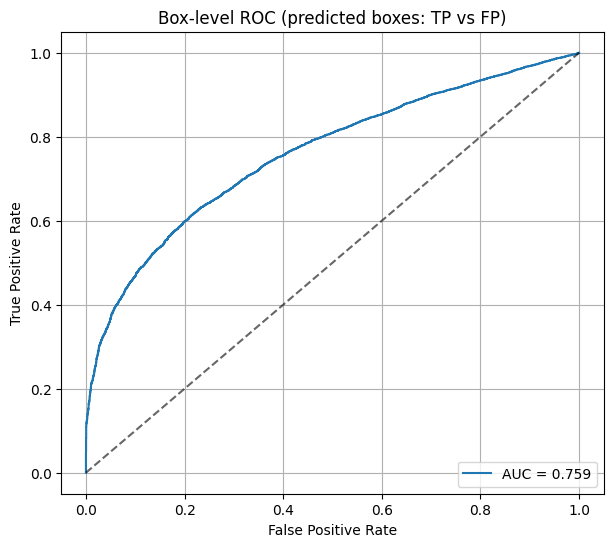

Done


In [28]:
# Full block: train evaluation + box-level ROC/AUC plotting
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision.ops import box_iou, nms
from sklearn.metrics import roc_curve, auc

# ---------- Helpers ----------
def coco_targets_to_xyxy(target):
    if len(target) == 0:
        return torch.zeros((0,4), dtype=torch.float32), torch.zeros((0,), dtype=torch.int64)
    boxes, labels = [], []
    for obj in target:
        x,y,w,h = obj["bbox"]
        boxes.append([x, y, x + w, y + h])
        labels.append(int(obj["category_id"]))
    return torch.tensor(boxes, dtype=torch.float32), torch.tensor(labels, dtype=torch.int64)

def postprocess_preds(pred, conf_thr, nms_iou, topk):
    boxes = pred["boxes"].detach().cpu()
    scores = pred["scores"].detach().cpu()
    labels = pred["labels"].detach().cpu()
    keep = scores >= conf_thr
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    if scores.numel() == 0:
        return boxes, scores, labels
    keep_all = []
    for c in labels.unique():
        idx = (labels==c).nonzero(as_tuple=True)[0]
        keep_idx = nms(boxes[idx], scores[idx], nms_iou)
        keep_all.append(idx[keep_idx])
    keep_all = torch.cat(keep_all) if len(keep_all) else torch.tensor([], dtype=torch.int64)
    boxes, scores, labels = boxes[keep_all], scores[keep_all], labels[keep_all]
    order = torch.argsort(scores, descending=True)
    boxes, scores, labels = boxes[order], scores[order], labels[order]
    if topk is not None and scores.numel() > topk:
        boxes, scores, labels = boxes[:topk], scores[:topk], labels[:topk]
    return boxes, scores, labels

def match_counts_and_roc(pred_boxes, pred_labels, pred_scores, gt_boxes, gt_labels, iou_thr):
    """
    Returns:
      tp, fp, fn (counts for overall metrics)
      y_true_box, y_score_box lists for box-level ROC (per prediction)
    """
    if len(pred_boxes) == 0:
        # all GT are missed (no pred), no box-level samples
        return 0, 0, int(len(gt_boxes)), [], []
    if len(gt_boxes) == 0:
        # all predictions are false positives
        y_true = [0]*len(pred_boxes)
        y_score = [float(s) for s in pred_scores.tolist()]
        return 0, len(pred_boxes), 0, y_true, y_score

    order = torch.argsort(pred_scores, descending=True)
    pred_boxes = pred_boxes[order]
    pred_labels = pred_labels[order]
    pred_scores = pred_scores[order]

    ious = box_iou(pred_boxes.float(), gt_boxes.float())
    used_gt = torch.zeros(len(gt_boxes), dtype=torch.bool)
    TP = FP = 0
    y_true = []
    y_score = []

    for i in range(len(pred_boxes)):
        same_class = (gt_labels == pred_labels[i])
        if same_class.sum().item() == 0:
            FP += 1
            y_true.append(0); y_score.append(float(pred_scores[i].item()))
            continue

        row = ious[i].clone()
        row[~same_class] = -1.0
        j = int(torch.argmax(row).item())
        best_iou = float(row[j].item())

        if best_iou >= iou_thr and (not used_gt[j]):
            used_gt[j] = True
            TP += 1
            y_true.append(1); y_score.append(float(pred_scores[i].item()))
        else:
            FP += 1
            y_true.append(0); y_score.append(float(pred_scores[i].item()))

    FN = int((~used_gt).sum().item())
    return TP, FP, FN, y_true, y_score

# ---------- Main: eval + ROC ----------
def evaluate_train_with_roc(model, train_loader, device,
                            conf_thr=0.35, topk=50, nms_iou=0.3, iou_thr=0.3,
                            max_images=None, plot_roc=True):
    model.eval()
    TP = FP = FN = 0
    all_y_true = []
    all_y_score = []
    seen = 0

    with torch.no_grad():
        for images, targets in train_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for pred, tgt in zip(outputs, targets):
                gt_boxes, gt_labels = coco_targets_to_xyxy(tgt)
                pb, ps, pl = postprocess_preds(pred, conf_thr, nms_iou, topk)
                tp, fp, fn, y_true, y_score = match_counts_and_roc(pb, pl, ps, gt_boxes, gt_labels, iou_thr)
                TP += tp; FP += fp; FN += fn
                all_y_true.extend(y_true)
                all_y_score.extend(y_score)

                seen += 1
                if max_images is not None and seen >= max_images:
                    break
            if max_images is not None and seen >= max_images:
                break

    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2*precision*recall/(precision+recall+1e-9)

    print("\n=== TRAIN DIAGNOSTIC (box-level) ===")
    print(f"conf={conf_thr} topK={topk} nms_iou={nms_iou} eval_iou={iou_thr}")
    print(f"TP={TP} FP={FP} FN={FN}")
    print(f"Precision={precision:.3f} Recall={recall:.3f} F1={f1:.3f}")
    print("====================================\n")

    # ROC / AUC (box-level)
    if len(all_y_true) == 0:
        print("No predicted boxes produced; ROC unavailable.")
        return {"TP":TP,"FP":FP,"FN":FN,"precision":precision,"recall":recall,"f1":f1}

    if len(set(all_y_true)) < 2:
        print("ROC unavailable: all predicted boxes are same label (all TP or all FP).")
        # still return counts
        return {"TP":TP,"FP":FP,"FN":FN,"precision":precision,"recall":recall,"f1":f1,
                "y_true":all_y_true,"y_score":all_y_score}

    fpr, tpr, _ = roc_curve(all_y_true, all_y_score)
    roc_auc = auc(fpr, tpr)
    print(f"Box-level ROC AUC = {roc_auc:.3f}")

    if plot_roc:
        plt.figure(figsize=(7,6))
        plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
        plt.plot([0,1],[0,1],'k--', alpha=0.6)
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("Box-level ROC (predicted boxes: TP vs FP)")
        plt.legend(loc="lower right")
        plt.grid(True)
        plt.show()

    return {"TP":TP,"FP":FP,"FN":FN,"precision":precision,"recall":recall,"f1":f1,
            "y_true":all_y_true,"y_score":all_y_score,"roc_auc":roc_auc}

# ---------- RUN (on train data) ----------
results = evaluate_train_with_roc(
    model,
    train_loader,   # <-- diagnostic eval on training set
    device,
    conf_thr=0.35,
    topk=50,
    nms_iou=0.3,
    iou_thr=0.3,
    max_images=None,
    plot_roc=True
)

print("Done")
